# NER
NER (Named_Entity_Relationship) is an NLP technique used to indentify and classify named entities in text.


In [ ]:
import spacy

In [ ]:
!python -m spacy download en_core_web_sm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 24.5 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [ ]:
nlp = spacy.load('en_core_web_sm')

In [ ]:
#Example 1
text = "Nokia is a company based out of Finland."
doc = nlp(text)
for ent in doc.ents:
  print(ent.text, ent.label_)

Nokia ORG
Finland GPE


In [ ]:
#Example 2
text = "Narendra Modi is the prime minister of India."
doc = nlp(text)
for ent in doc.ents:
  print(ent.text,ent.label_)

Narendra Modi PERSON
India GPE


In [ ]:
#Example 3 Organizations
text = "Xbox and Microsoft are gaming/technology companies"
doc = nlp(text)
for ent in doc.ents:
  print(ent.text, ent.label_)

Xbox ORG
Microsoft ORG


In [ ]:
#Example 4 Locations
text = "Delhi is the capital of India."
doc = nlp(text)
for ent in doc.ents:
  print(ent.text, ent.label_)

Delhi GPE
India GPE


In [ ]:
#Example 5 Dates
text = "India's Independence Day is held every year on 15th of August."
doc = nlp(text)
for ent in doc.ents:
  print(ent.text, ent.label_)

India GPE
Independence Day EVENT
15th of August DATE


In [ ]:
#Example 7 Percentage
text = "The company is presented to display an increase in oprational profits by 15% by the end of this quarter."
doc = nlp(text)
for ent in doc.ents:
  print(ent.text, ent.label_)

15% PERCENT
the end of this quarter DATE


In [ ]:
#Example 8 Extract only Person Entities
text = """Arjun was the main character of Mahabharta.
Howeveer, It was Karan who stole Lord Krishna's praise.
"""
doc = nlp(text)
for ent in doc.ents:
  if ent.label_ == "PERSON":
    print(ent.text, ent.label_)

Howeveer PERSON
Karan PERSON
Krishna PERSON


In [ ]:
#Example 9 Extract only organizations
text = """Valve Corporation has entered the console wars in 2026.
Becoming a major Competitor for XBOX, Sony and Nintendo.
"""
doc = nlp(text)
for ent in doc.ents:
  if ent.label_ == "ORG":
    print(ent.text, ent.label_)

Valve Corporation ORG
XBOX ORG
Sony ORG
Nintendo ORG


In [ ]:
#Example 10 Extract all entity types
text = """Michael Jackson was the most popular Pop-singers and dancers of his era.
He revoltionaized the dancing industry in the 1960s in America.
His networth was believed to be around $2 billion.
"""
doc = nlp(text)
for ent in doc.ents:
    print("Entity:", ent.text,
          "|Label:", ent.label_,
          "|Meaning:", spacy.explain(ent.label_))

Entity: Michael Jackson |Label: PERSON |Meaning: People, including fictional
Entity: the 1960s |Label: DATE |Meaning: Absolute or relative dates or periods
Entity: America |Label: GPE |Meaning: Countries, cities, states
Entity: around $2 billion |Label: MONEY |Meaning: Monetary values, including unit


In [ ]:
#11 NER visualization using displacy
from spacy import displacy
text = """Michael Jackson was the most popular Pop-singers and dancers of his era.
He revoltionaized the dancing industry in the 1960s in America.
His networth was believed to be around $2 billion.
"""
doc = nlp(text)
displacy.render(doc, style="ent", jupyter=True)

Counter({'PERSON': 3, 'GPE': 2})


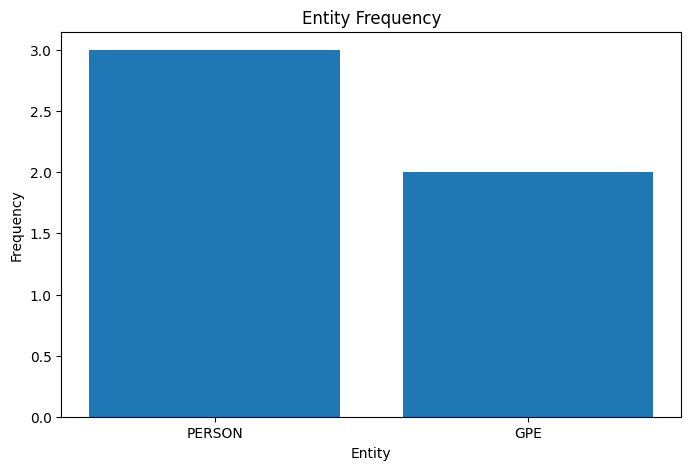

In [ ]:
#12 NER frequency visualization
from collections import Counter
import matplotlib.pyplot as plt
text = """World's most popular dancer was Michael Jackson.
America's most popular rapper is Eminem.
India's most popular singer is A.R. Rahman.
"""
doc = nlp(text)
entity_count = Counter(
    ent.label_ for ent in doc.ents
)
print(entity_count),
plt.figure(figsize =(8,5))
plt.bar(
    entity_count.keys(),
    entity_count.values()
)
plt.xlabel("Entity")
plt.ylabel("Frequency")
plt.title("Entity Frequency")
plt.show()

In [ ]:
#13 Create an NER dataframe
import pandas as pd
text = """World's most popular dancer was Michael Jackson.
America's most popular rapper is Eminem.
India's most popular singer is A.R. Rahman.
"""
doc = nlp(text)
df = []
for ent in doc.ents:
  df.append(
      {
          "Text": ent.text,
          "Label": ent.label_,
          "Description": spacy.explain(ent.label_)
      }
  )
df = pd.DataFrame(df)
df

,Text,Label,Description
0,Michael Jackson,PERSON,"People, including fictional"
1,America,GPE,"Countries, cities, states"
2,Eminem,PERSON,"People, including fictional"
3,India,GPE,"Countries, cities, states"
4,A.R. Rahman,PERSON,"People, including fictional"


,Text,Label,Description
0,"October 15, 2025",DATE,Absolute or relative dates or periods
1,Jane Doe,PERSON,"People, including fictional"
2,TechCorp Inc.,ORG,"Companies, agencies, institutions, etc."
3,$45 million,MONEY,"Monetary values, including unit"
4,New York,GPE,"Countries, cities, states"
5,25%,PERCENT,"Percentage, including ""%"""
6,European,NORP,Nationalities or religious or political groups
7,London,GPE,"Countries, cities, states"
8,Robert Smith,PERSON,"People, including fictional"
9,last Tuesday,DATE,Absolute or relative dates or periods


----------------------------------------
Named Entities:
----------------------------------------
October 15, 2025     DATE       Absolute or relative dates or periods 
Jane Doe             PERSON     People, including fictional 
TechCorp Inc.        ORG        Companies, agencies, institutions, etc. 
$45 million          MONEY      Monetary values, including unit 
New York             GPE        Countries, cities, states 
25%                  PERCENT    Percentage, including "%" 
European             NORP       Nationalities or religious or political groups 
London               GPE        Countries, cities, states 
Robert Smith         PERSON     People, including fictional 
last Tuesday         DATE       Absolute or relative dates or periods 
9:00 AM next month   TIME       Times smaller than a day 
the Federal Trade Commission ORG        Companies, agencies, institutions, etc. 
the fiscal year concludes DATE       Absolute or relative dates or periods 
December             DATE   

/tmp/ipykernel_1421/697190834.py:42: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = plt.cm.get_cmap('tab20', len(categories)).colors


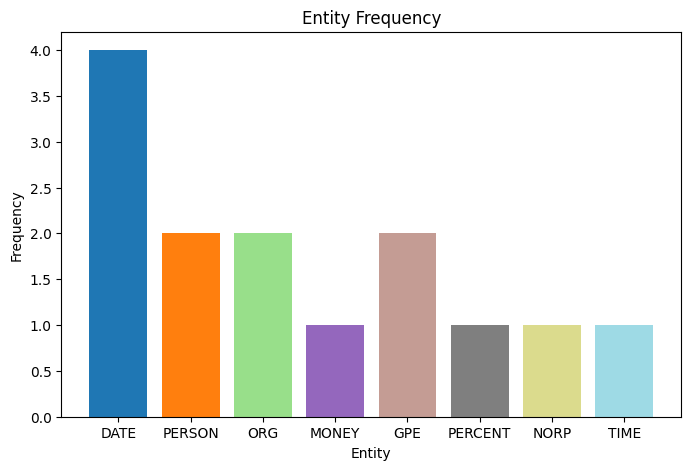

----------------------------------------


In [57]:
#14 Complete NER Program with visualization
text = """On October 15, 2025, CEO Jane Doe announced that TechCorp Inc. would acquire StartupXYZ for $45 million in New York.
The groundbreaking deal is expected to increase operational efficiency by 25% across their European headquarters in London.
Dr. Robert Smith, who joined the board last Tuesday, will lead the new initiative starting at 9:00 AM next month.
Regulatory approval from the Federal Trade Commission is anticipated before the fiscal year concludes in December.
"""
#Process Text
doc = nlp(text)
#Create a dataframe to display entites
df2 = []
for ent in doc.ents:
  df2.append(
      {
          "Text": ent.text,
          "Label": ent.label_,
          "Description": spacy.explain(ent.label_)
      }
  )
df2 = pd.DataFrame(df2)
# Display dataframe
from IPython.display import display
display(df2)
print("-"*40)
#Separately Display Entities
print("Named Entities:")
print("-"*40)
for ent in doc.ents:
 print(
     f"{ent.text:20} "
     f"{ent.label_:10} "
     f"{spacy.explain(ent.label_)} ")
print("Entity Frequency:")
entity_count = Counter(
    ent.label_ for ent in doc.ents
)
print(entity_count)
print("-"*40)

# Generate varying colors for each bar
categories = list(entity_count.keys())
values = list(entity_count.values())
colors = plt.cm.get_cmap('tab20', len(categories)).colors

plt.figure(figsize =(8,5))
plt.bar(
    categories,
    values,
    color=colors
)
plt.xlabel("Entity")
plt.ylabel("Frequency")
plt.title("Entity Frequency")
plt.show()
print("-"*40)
displacy.render(doc, style="ent", jupyter=True)

